# Exercise 14.2 – Overstrain failure
Status: **AWAITING HUMAN REVIEW**. KI-Unterstützung: Codex (Code, Auswertung, technische Prüfung). Studentischer Review steht aus.

## 1. Ziel der Aufgabe
Die [offizielle Aufgabe 14.2](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/1_self_study_session1.html) verlangt: OSF-Regel nach Type visualisieren; Entscheidungsgrenzen der Tiefen 1/2/4/8 nur aus Drehmoment und Verschleiß mit der 11.000-Hyperbel vergleichen; den [Kursbaum aus 13.1.6.2](https://noxthot.github.io/ws26_industrial_datascience_manuscript/2_act2/0_0_predictive_maintenance.html) um `wearadjTorque` und danach `Type` ergänzen. Gesucht sind Strukturänderung, kleinste nahezu trennende Tiefe und gelernte Schwellen. Quellen vollständig gelesen am **19.11.2026**. Keine HDF-/PWF-Modellstudie aus 14.3.

## 2. Daten und Methode
AI4I 2020: unveränderte synthetische UCI-Daten, [DOI](https://doi.org/10.24432/C5HS5C), CC BY 4.0. Der geprüfte Loader kontrolliert SHA256, 10.000 × 14, Datentypen, Fehlwerte und Duplikate. Ziel ist ausschließlich `OSF`; Fehlerflags und IDs werden nie Eingaben.

Ein Entscheidungsbaum teilt Daten anhand einzelner Merkmalsgrenzen. Eine gekrümmte Grenze lässt sich mit solchen achsenparallelen Schnitten nur stufenweise annähern. Das fachlich vorgegebene Produkt w·τ (Verschleiß in min, Drehmoment in Nm) kann die Regel als einfachen Schwellwert abbilden. Für L/M/H gelten laut Beschreibung 11.000/12.000/13.000 min·Nm, jeweils **streng überschritten**.

Wir übernehmen Seed 42, `min_samples_split=5`, `min_samples_leaf=5` und Tiefe 3 aus dem Kurs; für den verlangten Tiefenvergleich ändert sich nur die Tiefe. Type wird durch zwei feste Indikatoren (M/H, L als Referenz) codiert, ohne künstliche Rangfolge. Die Kursbasis enthält fünf Messgrößen sowie `temp_diff` und `power`; diese werden ausschließlich für den geforderten OSF-Kursbaum berechnet.

Die vollständigen Daten dienen der ausdrücklich gefragten **erklärenden Anpassung**, nicht als unabhängiger Leistungstest. „Nahezu perfekt“ bedeutet hier transparent höchstens zwei Fehler in 10.000 Zeilen; dies ist eine Arbeitsdefinition, keine Kursvorgabe. Die kleinste Tiefe wird nur für diese Anpassung unter 1–8 bestimmt. Zusätzlich wird der vorab feste Kursbaum der Tiefe 3 auf einem stratifizierten 80/20-Split geprüft: nur TRAIN beim Fit, TEST nicht zur Wahl von Tiefe oder Merkmalen. Keine gelernte Skalierung; Produkt und Indikatoren sind zeilenweise fest definiert.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root))
from sessions.ch14.overstrain import analyze, tree, GROUPS, TORQUE
from sessions.ch14.tool_wear import WEAR
from sessions.ch10.ai4i_data import verify_file
output = root / "outputs/ch14/exercise_14_2"
output.mkdir(parents=True, exist_ok=True)
data, fitting, heldout, models, summary = analyze()
print("Rohdaten-SHA256:", verify_file())
print(summary)
fitting.to_csv(output / "fitting_comparison.csv", index=False)
heldout.to_csv(output / "heldout_comparison.csv", index=False)
summary["smallest_near_perfect_depth"] = int(fitting.loc[(fitting.Merkmale == "+ Produkt + Type") & (fitting.Fehler <= 2), "Tiefe"].min())
(output / "summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
display(fitting.loc[fitting.Tiefe <= 3])
print("Fester 80/20-Test, ausschließlich Tiefe 3:")
display(heldout)

Rohdaten-SHA256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e
{'rows': 10000, 'osf': 98, 'rule_mismatches': 0, 'train_rows': 8000, 'test_rows': 2000, 'train_osf': 78, 'test_osf': 20, 'seed': 42}


,Merkmale,Tiefe,Fehler,FP,FN,TP,F1
0,Kursbasis,1,98,0,98,0,0.000000
1,Kursbasis,2,58,14,44,54,0.650602
2,Kursbasis,3,43,16,27,71,0.767568
8,+ Produkt,1,27,27,0,98,0.878924
9,+ Produkt,2,27,27,0,98,0.878924
10,+ Produkt,3,22,17,5,93,0.894231
16,+ Produkt + Type,1,27,27,0,98,0.878924
17,+ Produkt + Type,2,17,8,9,89,0.912821
18,+ Produkt + Type,3,2,0,2,96,0.989691


Fester 80/20-Test, ausschließlich Tiefe 3:


,Merkmale,Tiefe,Fehler,FP,FN,TP,F1
0,Kursbasis,3,14,5,9,11,0.611111
1,+ Produkt,3,8,4,4,16,0.800000
2,+ Produkt + Type,3,1,0,1,19,0.974359


## 3. Durchführung: Regel und Entscheidungsgrenzen
Die erste Grafik trennt Type, zeigt alle Beobachtungen und hebt OSF hervor. Die drei vorgegebenen Hyperbeln werden mit den tatsächlich markierten Fällen verglichen. Bei Verschleiß 0 ist die Hyperbel nicht definiert; dort ist das Produkt 0.

Die zweite Grafik zeigt die Klassenentscheidungen der vier geforderten Bäume auf allen Daten. Die schwarze Referenz gilt **nur für Type L**: Da Type hier absichtlich fehlt, ist sie keine gemeinsame exakte Grenze für alle Varianten. Diese Abbildungen zeigen Anpassung und Geometrie, keine TEST-Leistung. Die Baumstruktur ist zusätzlich als Text ausgegeben; im HTML lassen sich die Grafiken durch Anklicken in Originalauflösung öffnen.

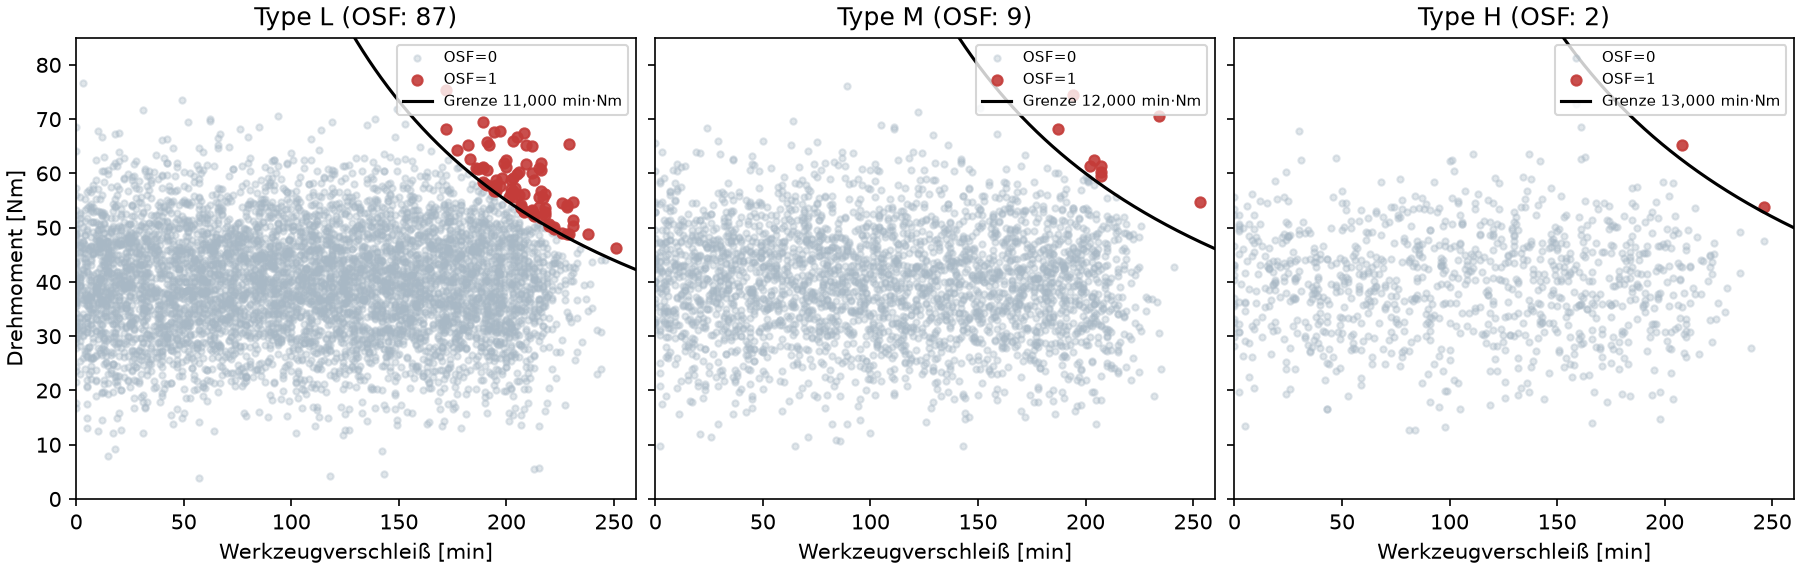

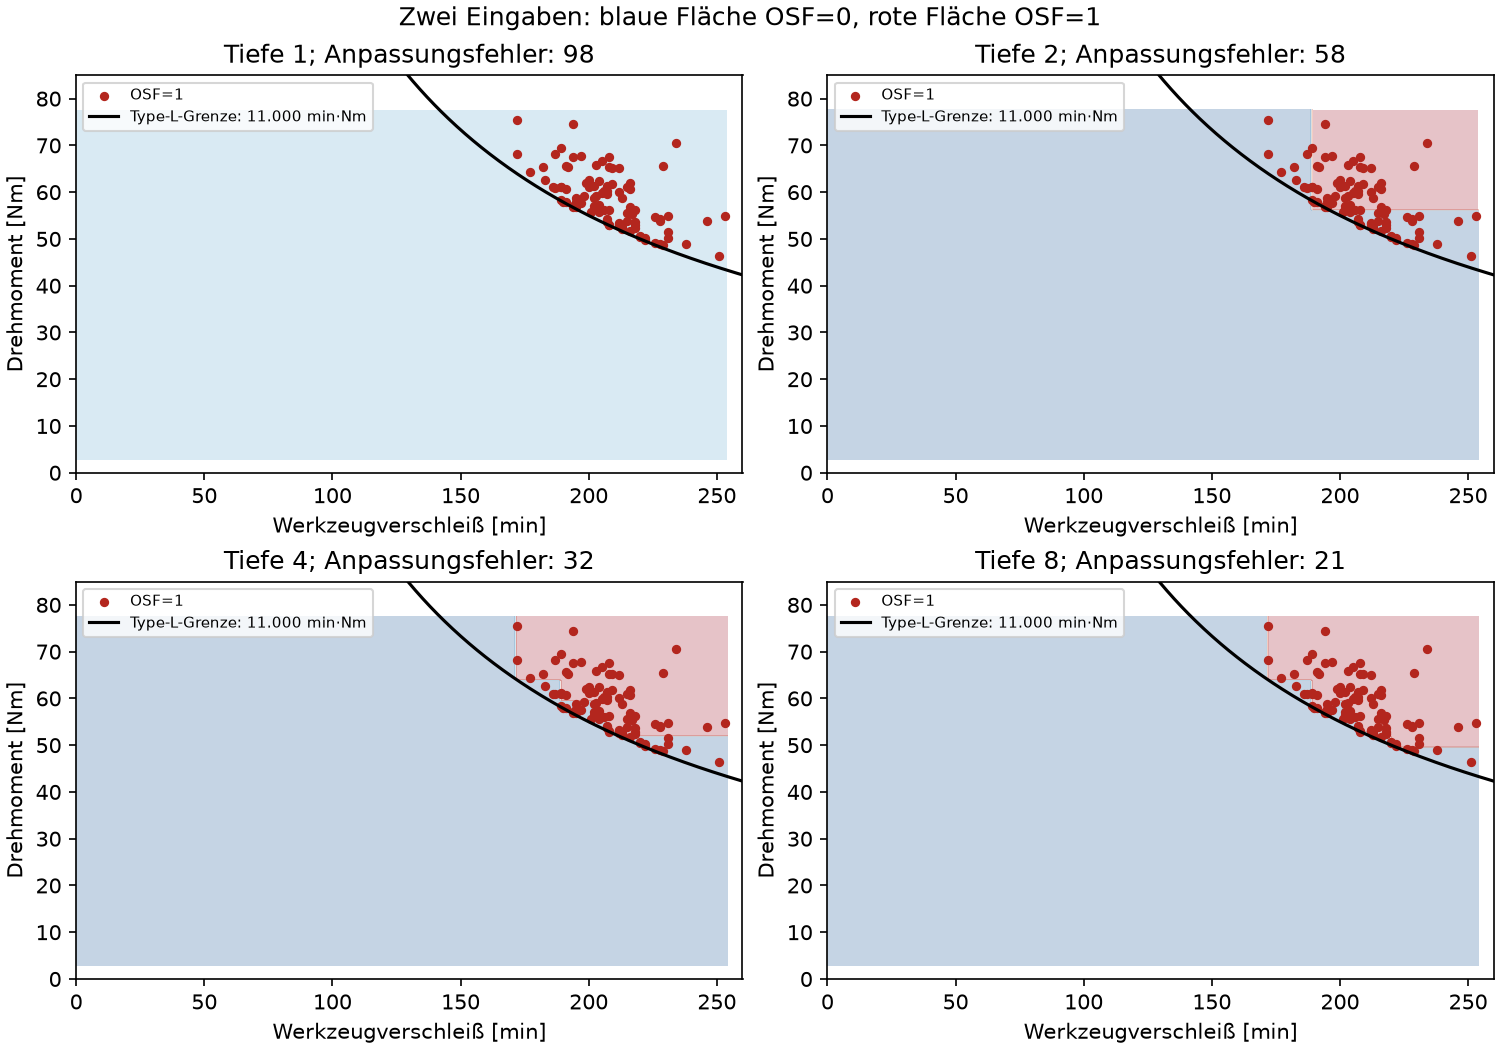

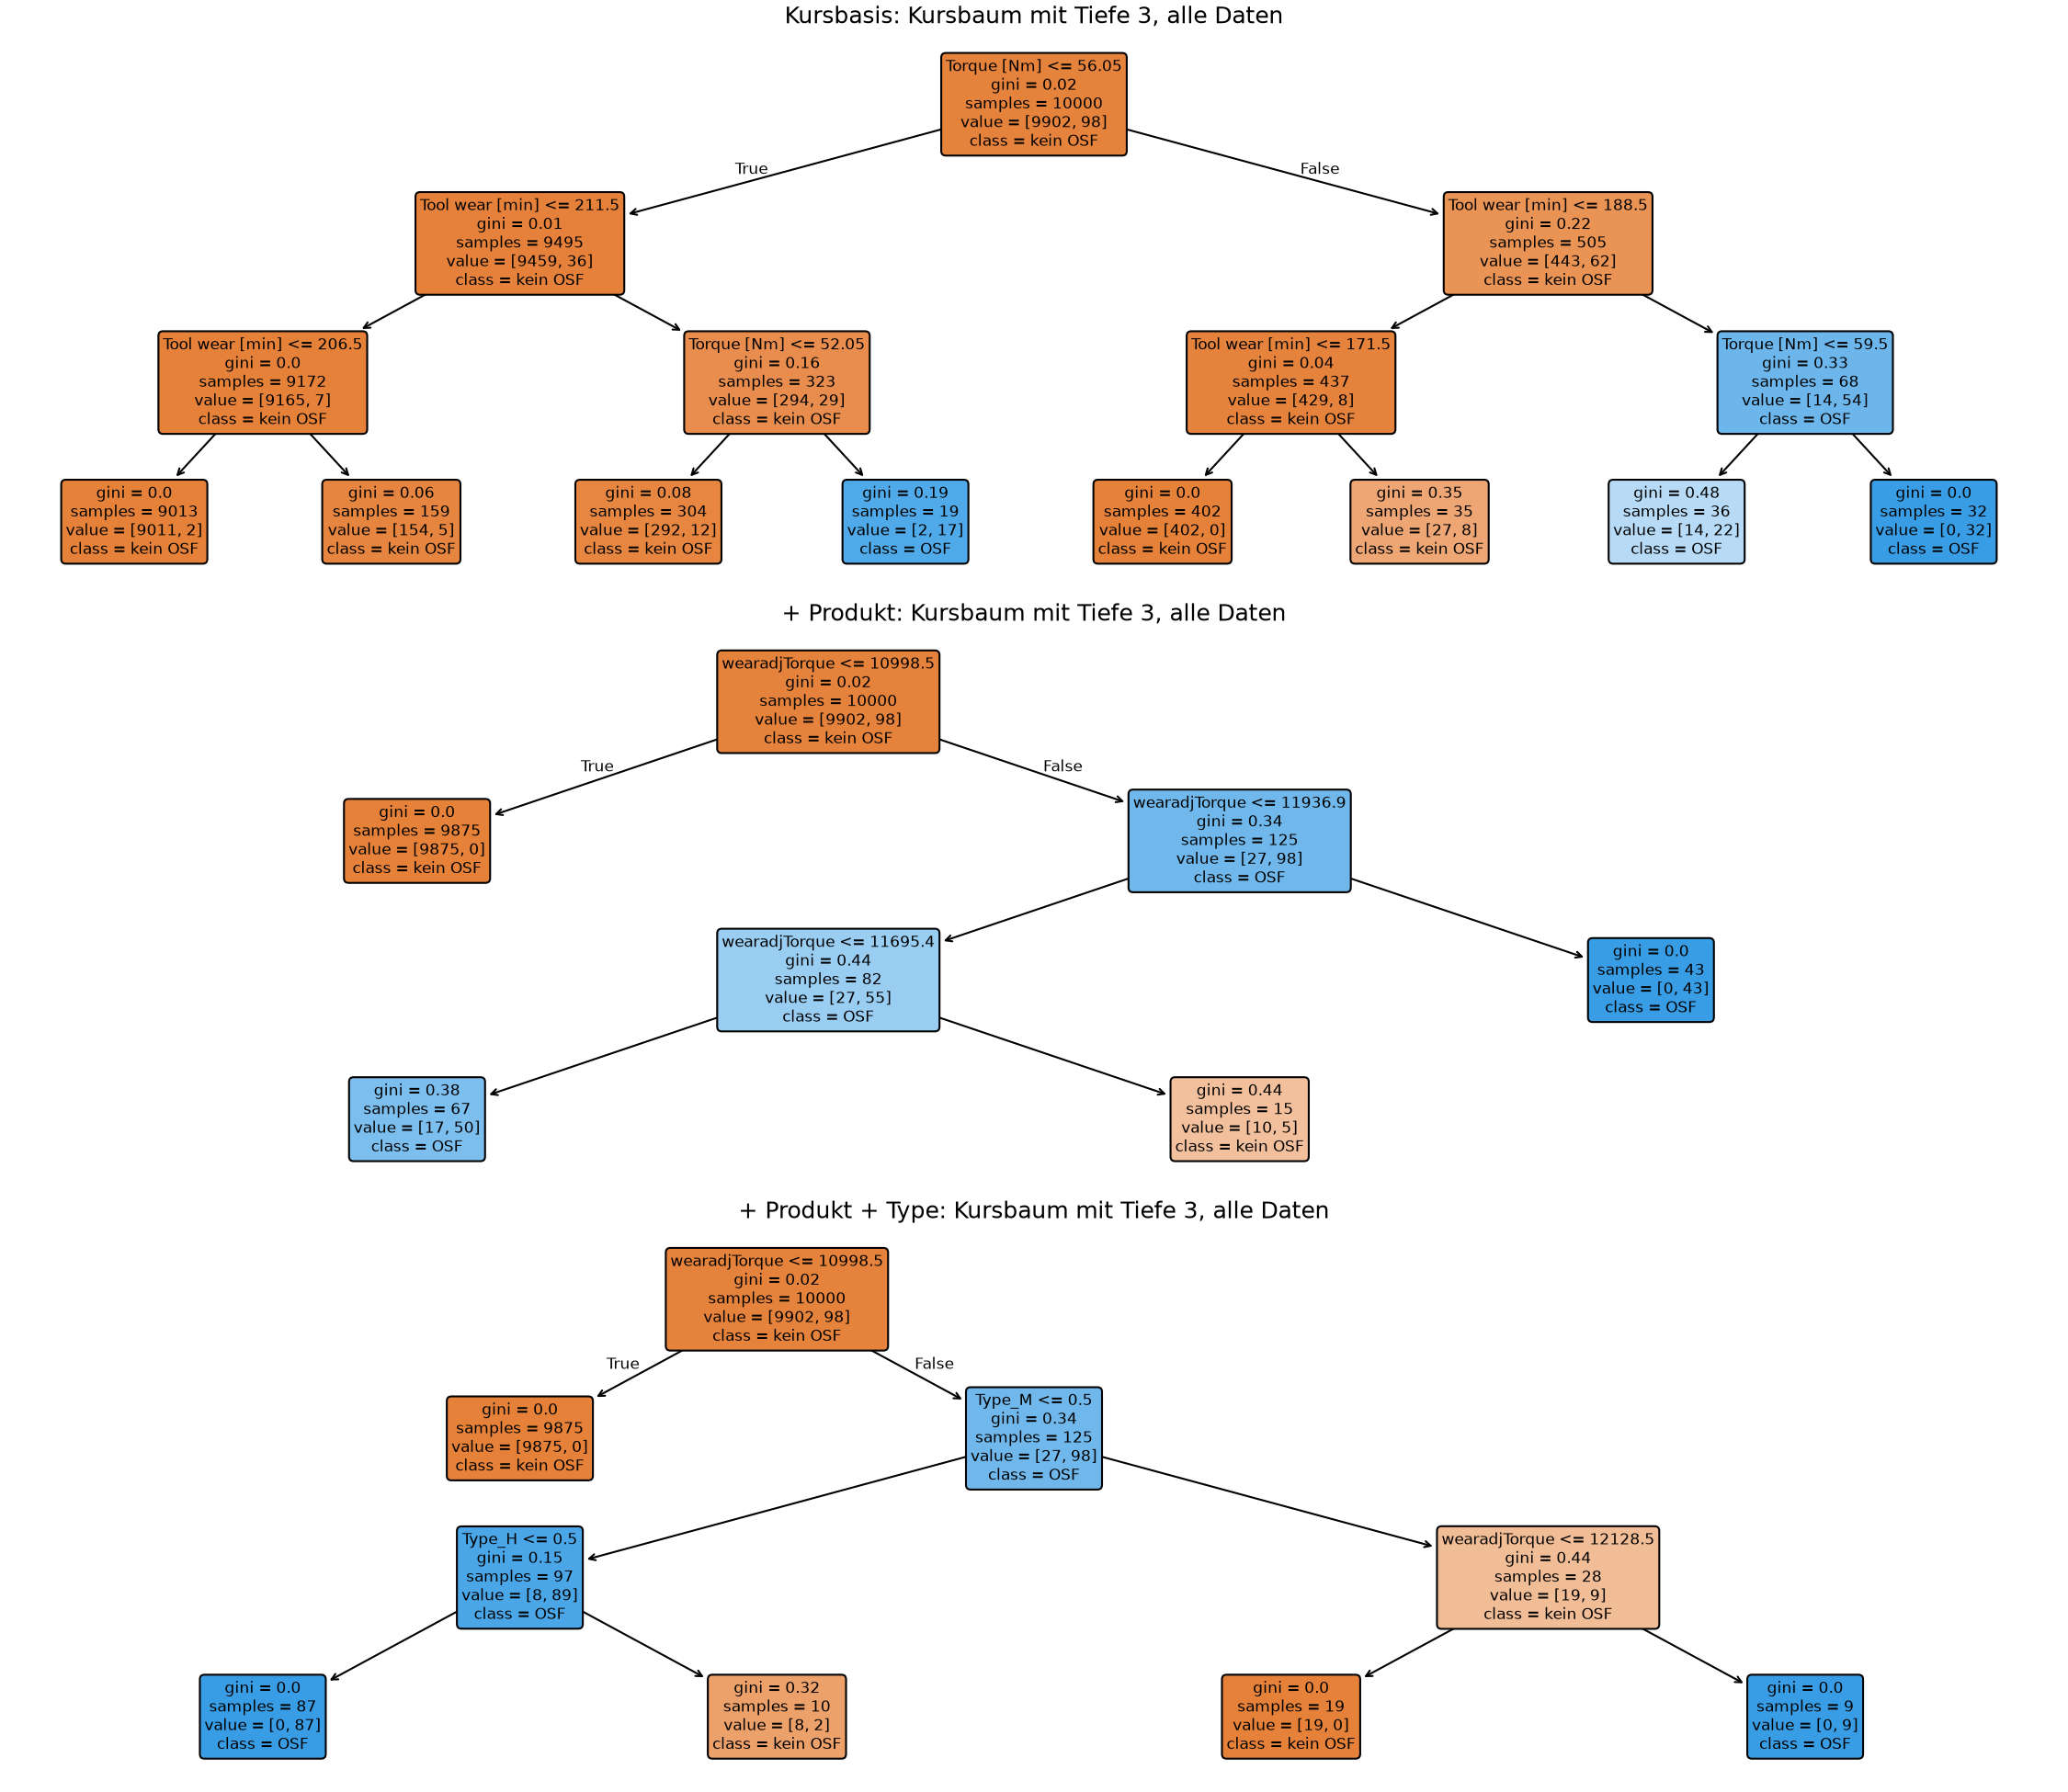

+ Produkt + Type
|--- wearadjTorque <= 10998.50
|   |--- class: 0
|--- wearadjTorque >  10998.50
|   |--- Type_M <= 0.50
|   |   |--- Type_H <= 0.50
|   |   |   |--- class: 1
|   |   |--- Type_H >  0.50
|   |   |   |--- class: 0
|   |--- Type_M >  0.50
|   |   |--- wearadjTorque <= 12128.50
|   |   |   |--- class: 0
|   |   |--- wearadjTorque >  12128.50
|   |   |   |--- class: 1



In [2]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.tree import plot_tree, export_text
from IPython.display import Image

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained", sharex=True, sharey=True)
x = np.linspace(100, 260, 400)
for ax, variant, limit in zip(axes, ["L", "M", "H"], [11000, 12000, 13000]):
    subset = data.loc[data.Type.eq(variant)]
    for flag, color, label in [(0, "#a8b8c5", "OSF=0"), (1, "#c43c39", "OSF=1")]:
        rows = subset.loc[subset.OSF.eq(flag)]
        ax.scatter(rows[WEAR], rows[TORQUE], s=9 if flag == 0 else 24, alpha=.35 if flag == 0 else .9, color=color, label=label)
    ax.plot(x, limit/x, color="black", label=f"Grenze {limit:,} min·Nm")
    ax.set(title=f"Type {variant} (OSF: {subset.OSF.sum()})", xlabel="Werkzeugverschleiß [min]", xlim=(0, 260), ylim=(0, 85))
    ax.legend(fontsize=7, loc="upper right")
axes[0].set_ylabel("Drehmoment [Nm]")
fig.savefig(output / "01_osf_rule.png", dpi=150)
plt.close(fig); display(Image(filename=str(output / "01_osf_rule.png")))

fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")
for ax, depth in zip(axes.flat, [1, 2, 4, 8]):
    columns = [WEAR, TORQUE]
    model = tree(depth).fit(data[columns], data.OSF)
    DecisionBoundaryDisplay.from_estimator(model, data[columns], response_method="predict", grid_resolution=250, alpha=.25, cmap="RdBu_r", ax=ax)
    marked = data.loc[data.OSF.eq(1)]
    ax.scatter(marked[WEAR], marked[TORQUE], s=12, color="#b3261e", label="OSF=1")
    ax.plot(x, 11000/x, color="black", label="Type-L-Grenze: 11.000 min·Nm")
    ax.set(title=f"Tiefe {depth}; Anpassungsfehler: {(model.predict(data[columns]) != data.OSF).sum()}", xlabel="Werkzeugverschleiß [min]", ylabel="Drehmoment [Nm]", xlim=(0,260), ylim=(0,85))
    ax.legend(fontsize=7)
fig.suptitle("Zwei Eingaben: blaue Fläche OSF=0, rote Fläche OSF=1")
fig.savefig(output / "02_decision_boundaries.png", dpi=150)
plt.close(fig); display(Image(filename=str(output / "02_decision_boundaries.png")))

fig, axes = plt.subplots(3, 1, figsize=(15, 13), layout="constrained")
texts = []
for ax, (name, columns) in zip(axes, GROUPS.items()):
    model = models[name, 3]
    plot_tree(model, feature_names=columns, class_names=["kein OSF", "OSF"], filled=True, rounded=True, fontsize=8, ax=ax, precision=2)
    ax.set_title(name + ": Kursbaum mit Tiefe 3, alle Daten")
    texts.append(name + "\n" + export_text(model, feature_names=columns, decimals=2))
fig.savefig(output / "03_tree_structure.png", dpi=150)
plt.close(fig); display(Image(filename=str(output / "03_tree_structure.png")))
(output / "tree_structure.txt").write_text("\n".join(texts), encoding="utf-8")
print(texts[-1])

## 4. Ergebnisse und kurze Interpretation
Die Tabellen oben unterscheiden Anpassung und unabhängigen festen TEST-Split. Die Prüfung der beschriebenen Type-Regel und die kleinste nahezu trennende Tiefe stehen in der folgenden Zusammenfassung; alle Zahlen werden aus den Daten berechnet.

In [3]:
print(f"OSF: {summary['osf']} von {summary['rows']}; Abweichungen von der beschriebenen Type-Regel: {summary['rule_mismatches']}.")
print(f"Kleinste Tiefe mit höchstens zwei Anpassungsfehlern (Produkt + Type): {summary['smallest_near_perfect_depth']}.")
display(fitting.loc[fitting.Tiefe.isin([1, 2, 3, 4, 8])])

OSF: 98 von 10000; Abweichungen von der beschriebenen Type-Regel: 0.
Kleinste Tiefe mit höchstens zwei Anpassungsfehlern (Produkt + Type): 3.


,Merkmale,Tiefe,Fehler,FP,FN,TP,F1
0,Kursbasis,1,98,0,98,0,0.000000
1,Kursbasis,2,58,14,44,54,0.650602
2,Kursbasis,3,43,16,27,71,0.767568
3,Kursbasis,4,32,5,27,71,0.816092
7,Kursbasis,8,18,6,12,86,0.905263
8,+ Produkt,1,27,27,0,98,0.878924
9,+ Produkt,2,27,27,0,98,0.878924
10,+ Produkt,3,22,17,5,93,0.894231
11,+ Produkt,4,21,13,8,90,0.895522
15,+ Produkt,8,14,8,6,92,0.929293


## 5. Interpretation und Grenzen
Alle 98 OSF-Markierungen stimmen mit der vorgegebenen Type-Regel überein (L: 87, M: 9, H: 2). Bei Tiefe 3 sinken die Anpassungsfehler von **43** (Kursbasis) über **22** (+ Produkt) auf **2** (+ Produkt + Type). Tiefe **3** ist unter den geprüften Tiefen 1–8 die kleinste mit höchstens zwei Fehlern. Der erste Produktschnitt liegt bei **10.998,5 min·Nm**, für M folgt **12.128,5 min·Nm**. Für H wird keine eigene 13.000-Grenze gelernt: die beiden positiven H-Fälle bleiben wegen der Mindestblattgröße in einem gemischten Blatt und werden verfehlt.

Im festen TEST-Split (2.000 Zeilen, 20 OSF) betragen die Fehlerzahlen **14 / 8 / 1**, die F1-Werte **0,6111 / 0,8000 / 0,9744** für diese drei Varianten. Dies sind gemessene Werte dieses einen Splits; die nahezu perfekte Anpassung ist davon getrennt.

Das Produkt ermöglicht einen direkten ersten Schnitt statt einer Treppe aus Drehmoment- und Verschleißgrenzen. Type erlaubt danach unterschiedliche Entscheidungen für die Varianten. Gelernte Schwellen sind Mittelpunkte benachbarter beobachteter Werte; sie müssen deshalb nicht genau 11.000/12.000/13.000 sein. Die Struktur zeigt den konkreten Unterschied.

„Nahezu perfekt“ ist hier auf die **Anpassung** bezogen. Ein seltener Fehler kann trotz hoher Gesamtgenauigkeit übersehen werden; deshalb stehen Fehlerzahl, FP, FN und F1 neben der Struktur. Die Zusatzprüfung enthält nur rund ein Fünftel der seltenen OSF-Fälle und ist entsprechend unsicher. Sie begründet keine allgemeine Modellüberlegenheit. Es wurden keine weiteren Seeds oder externen Maschinen geprüft.

Die bekannte synthetische Regel wird nachgebildet, kein realer Ausfallmechanismus kausal bewiesen. Die Mindestblattgröße des Kursbaums kann einzelne seltene Fälle bewusst zusammenfassen; größere Tiefe garantiert daher keine fehlerfreie Trennung. Der vollständige Datenvergleich und die feste TEST-Prüfung sind getrennte Experimente; die TEST-Daten werden nicht zur Optimierung verwendet. Originaldaten und frühere Lösungen bleiben unverändert.

**Reproduktion:** `scripts/uv.cmd run --offline --locked python scripts/build_exercise_14_2.py --check-html`. Notebook und eigenständiges HTML sind die vorgesehenen Lesedateien; kein PDF wird in 14.2 verlangt. Kein studentischer Review oder Merge erfolgt.